# Ex 3, group 8:
# Boosting algorithms

### Esteban Càrdenas ID: 2183905
### Libero Pollini ID: 2206131
### Matteo Modolo ID:2200984
### Niccolò De Poli  ID:2197920

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# AdaBoost Algorithm
from sklearn.ensemble import AdaBoostClassifier

# Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier

# XGBoost
import xgboost
from xgboost import XGBClassifier
from xgboost import plot_importance, to_graphviz, plot_tree

print("XGBoost version:", xgboost.__version__)

mycmap = "winter"
mpl.rcParams["image.cmap"] = mycmap
plt.rcParams["font.size"] = 13

XGBoost version: 3.2.0


## Read and split data

Note: data was generated using the notebook `gen-XGB-26.ipynb`, provided by the professor.

In [ ]:
np.random.seed(12345)

dname = "./DATA/"
str0 = "_XGB_26.dat"
fnamex = dname + "x" + str0
fnamey = dname + "y" + str0
x = np.loadtxt(fnamex, delimiter=" ", dtype=float)
y = np.loadtxt(fnamey)
y = y.astype(int)
N, L = len(x), len(x[0])

N_train = int(0.75 * N)
x_train, y_train = x[:N_train], y[:N_train]
x_test, y_test = x[N_train:], y[N_train:]
print(f"N={N}, N_train={N_train}, L={L}")

N=5000, N_train=3750, L=4


### Scatter plot on \[i,j\] feature plane

[-31.608 -29.544   6.773   9.554] 0
[46.451 15.318 24.891 15.357] 0
[ 24.771  46.131 -49.161 -39.356] 0
[-20.13   15.641  30.981  37.218] 0
[46.465 22.369 14.248 21.745] 0


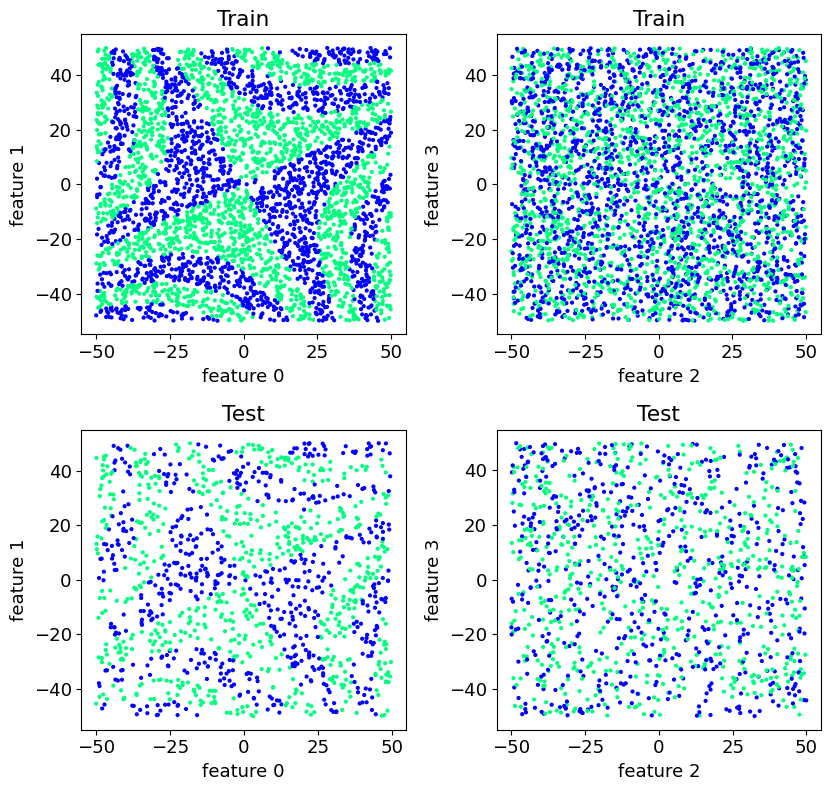

In [ ]:
def scat(ax, x, y, i=0, j=1, s=4, title=""):
    # scatter plot of the data in the plane of features i and j
    ax.scatter(x[:, i], x[:, j], s=s, c=y)
    ax.set_xlabel(f"feature {i}")
    ax.set_ylabel(f"feature {j}")
    ax.set_title(title)


# print the first 5 data points
for n in range(5):
    print(x[n], y[n])

# print feature plots for the training and test sets
fig, AX = plt.subplots(2, 2, figsize=(8.5, 8.1))
scat(AX[0, 0], x_train, y_train, title="Train")
scat(AX[0, 1], x_train, y_train, i=2, j=3, title="Train")
scat(AX[1, 0], x_test, y_test, title="Test")
scat(AX[1, 1], x_test, y_test, i=2, j=3, title="Test")
fig.tight_layout()
plt.show()

In [ ]:
def classify(clf=GradientBoostingClassifier(), show=False):
    # GradientBoostingClassifier():
    #   n_estimators = 100 (default)
    #   loss function = deviance(default) used in Logistic Regression
    # XGBClassifier()
    #   n_estimators = 100 (default)
    #   max_depth = 3 (default?)

    clf.fit(x_train, y_train)  # train the model on the training set
    y_hat = clf.predict(x_test)  # predict the labels of the test set

    print(
        "errors: {:.2f}%   Accuracy={:.3f}".format(
            100 * (1 - clf.score(x_test, y_test)), clf.score(x_test, y_test)
        )
    )
    S = 50  # size of the square grid
    dx = 1
    x_seq = np.arange(-S, S + dx, dx)  # sequence of points for the grid
    nx = len(x_seq)
    x_plot = np.zeros((nx * nx, L))  # grid of points
    print("shape of x_plot=", x_plot.shape)
    q = 0
    for i in range(nx):
        for j in range(nx):
            x_plot[q, :2] = [
                x_seq[i],
                x_seq[j],
            ]  # only the first two features are used for the artificial grid
            q += 1
    y_plot = clf.predict(x_plot)  # predict the labels of the grid points

    fig, AX = plt.subplots(1, 2, figsize=(8.2, 4))
    scat(AX[0], x_plot[:], y_plot, s=dx, title="predicted")
    scat(AX[1], x_train[:], y_train, title="training set")
    fig.tight_layout()
    plt.show()

    if show:
        dump_list = clf.get_booster().get_dump()  # get the list of trees in the model
        num_trees = len(dump_list)
        print("num_trees=", num_trees)

        fig, AX = plt.subplots(2, 1, figsize=(12, 5))
        for i in range(min(2, num_trees)):
            ax = AX[i]
            plot_tree(clf, num_trees=i, ax=ax)
        fig.savefig("DATA/tree-classif.png", dpi=400, pad_inches=0.02)
        plt.show()

### Classify
If the “objective” hyperparameter is left unspecified, XGBClassifier looks at the data and chooses automatically the loss functions and the evaluation metrics (--> WARNING)

## XGBoost
https://xgboost.readthedocs.io/en/stable/python/python_api.html

errors: 6.64%   Accuracy=0.934
shape of x_plot= (10201, 4)


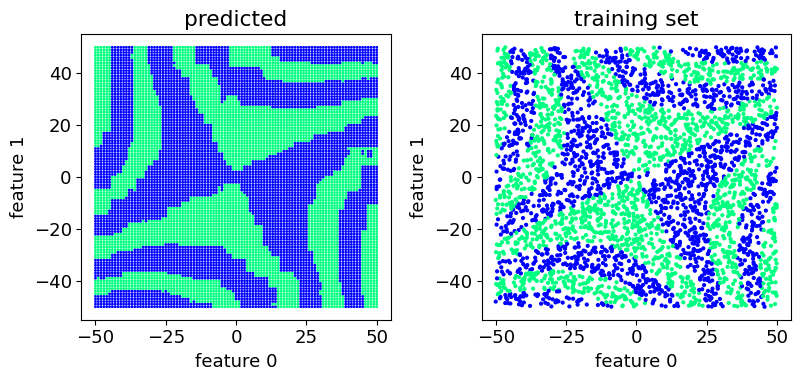

num_trees= 100


/home/niccolo/.local/lib/python3.13/site-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` insetad. 
  warnings.warn(
/home/niccolo/.local/lib/python3.13/site-packages/xgboost/plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` insetad. 
  warnings.warn(


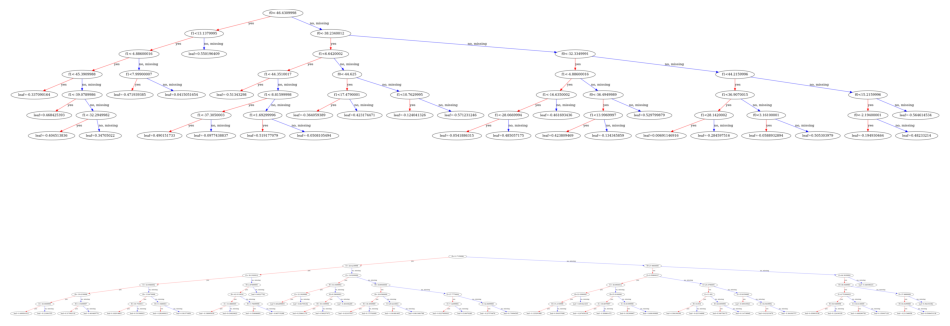

In [ ]:
model = XGBClassifier(
    seed=1, objective="binary:logistic", importance_type="gain"
)  # weight, cover, ...
# learning_rate=0.4,
# reg_lambda=0.001,
# n_estimators=30)

classify(model, show=True)

gain
[0.41903338 0.44306126 0.06554136 0.07236399]


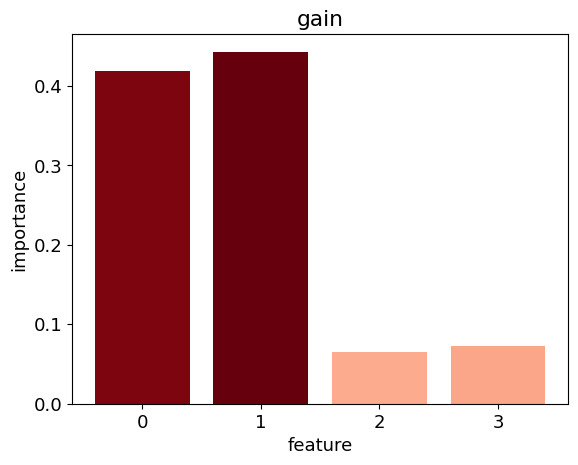

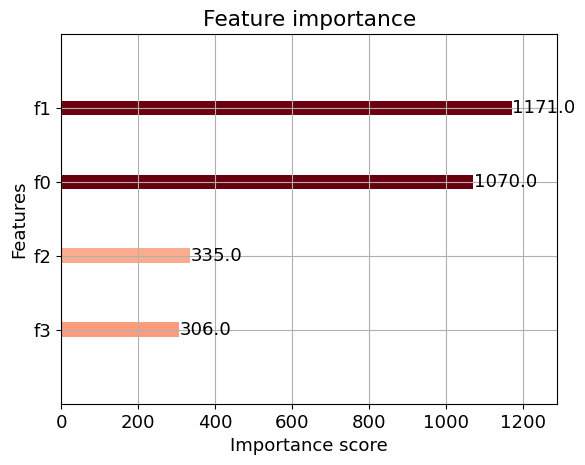

In [ ]:
# https://machinelearningmastery.com/feature-importance-and-feature-selection-with-xgboost-in-python/
# feature importance

print(model.importance_type)
print(model.feature_importances_)
# plot
my_cmap = plt.get_cmap("Reds")
# rescale the feature importances to the range [0.3,1] for better visualization
rescale = lambda y: 0.3 + 0.7 * (y - np.min(y)) / (np.max(y) - np.min(y))
plt.bar(
    range(len(model.feature_importances_)),
    model.feature_importances_,
    color=my_cmap(rescale(model.feature_importances_)),
)
plt.xlabel("feature")
plt.ylabel("importance")
plt.xticks(np.arange(L))
plt.title(model.importance_type)
plt.show()

rescale_r = lambda y: 0.3 + 0.7 * (np.max(y) - y) / (np.max(y) - np.min(y))
plot_importance(model, color=my_cmap(rescale_r(model.feature_importances_)))
plt.show()

Documentation: https://xgboost.readthedocs.io/en/stable/python/python_api.html

    ‘weight’: the number of times a feature is used to split the data across all trees.

    ‘gain’: the average gain across all splits the feature is used in.

    ‘cover’: the average coverage across all splits the feature is used in.

    ‘total_gain’: the total gain across all splits the feature is used in.

    ‘total_cover’: the total coverage across all splits the feature is used in.


0 weight [1070. 1171.  335.  306.]
1 gain [3.84043288 4.06064796 0.6006853  0.66321456]
2 total_gain [4109.26318359 4755.01904297  201.22956848  202.94364929]
3 cover [73.71099854 66.86531067 77.84243011 62.61100388]
4 total_cover [78870.765625   78299.28125    26077.21289062 19158.96679688]


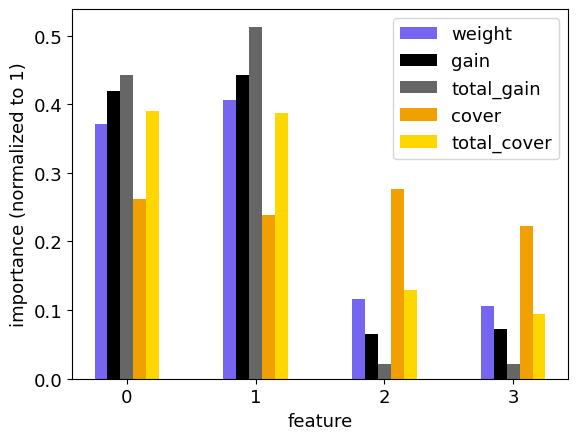

In [ ]:
# if the importance type is “total_gain”, then the score is sum of loss change for each split from all trees.
list_type = ["weight", "gain", "total_gain", "cover", "total_cover"]
list_col = ["#7565F0", "k", "#666666", "#F0A000", "gold"]

for i, t in enumerate(list_type):
    feature_imp = model.get_booster().get_score(importance_type=t)
    keys = list(feature_imp.keys())
    values = np.array(list(feature_imp.values()))
    print(i, t, values)
    values = values / np.sum(values)
    plt.bar(
        np.arange(L) + (i - L / 2) / 10, values, color=list_col[i], width=0.1, label=t
    )
plt.xlabel("feature")
plt.ylabel("importance (normalized to 1)")
plt.xticks(np.arange(L))
plt.legend()
plt.show()

## Gradient Boosting from Scikit-learn

errors: 19.76%   Accuracy=0.802
shape of x_plot= (10201, 4)


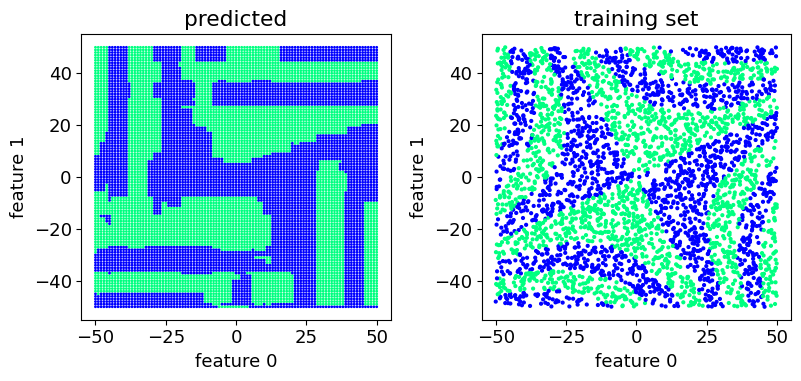

In [8]:
# GradientBoostingClassifier(), use the deafault parameters
classify()

## AdaBoost

errors: 40.72%   Accuracy=0.593
shape of x_plot= (10201, 4)


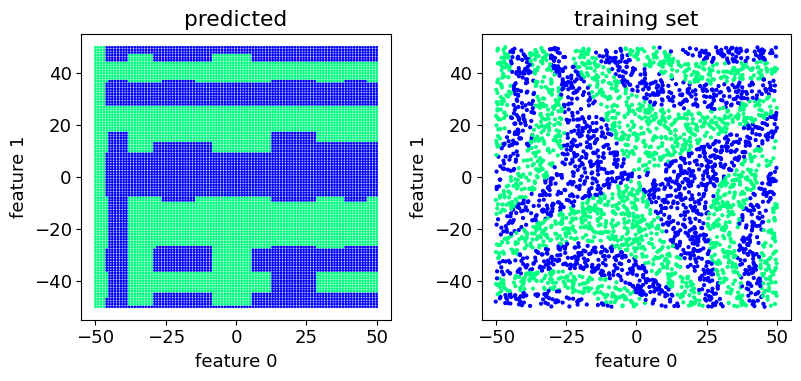

In [ ]:
classify(clf=AdaBoostClassifier(learning_rate=0.8, n_estimators=150))

## Ex 3.1

To avoid that the algorithm would be biased in the classification from a simple inbalance in the labels set we consider the ratio of these and exploit the attribute "scale_pos_weight" of the class

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import math

In [11]:
ratio = float(np.sum(y_train == 0)) / np.sum(y_train == 1)

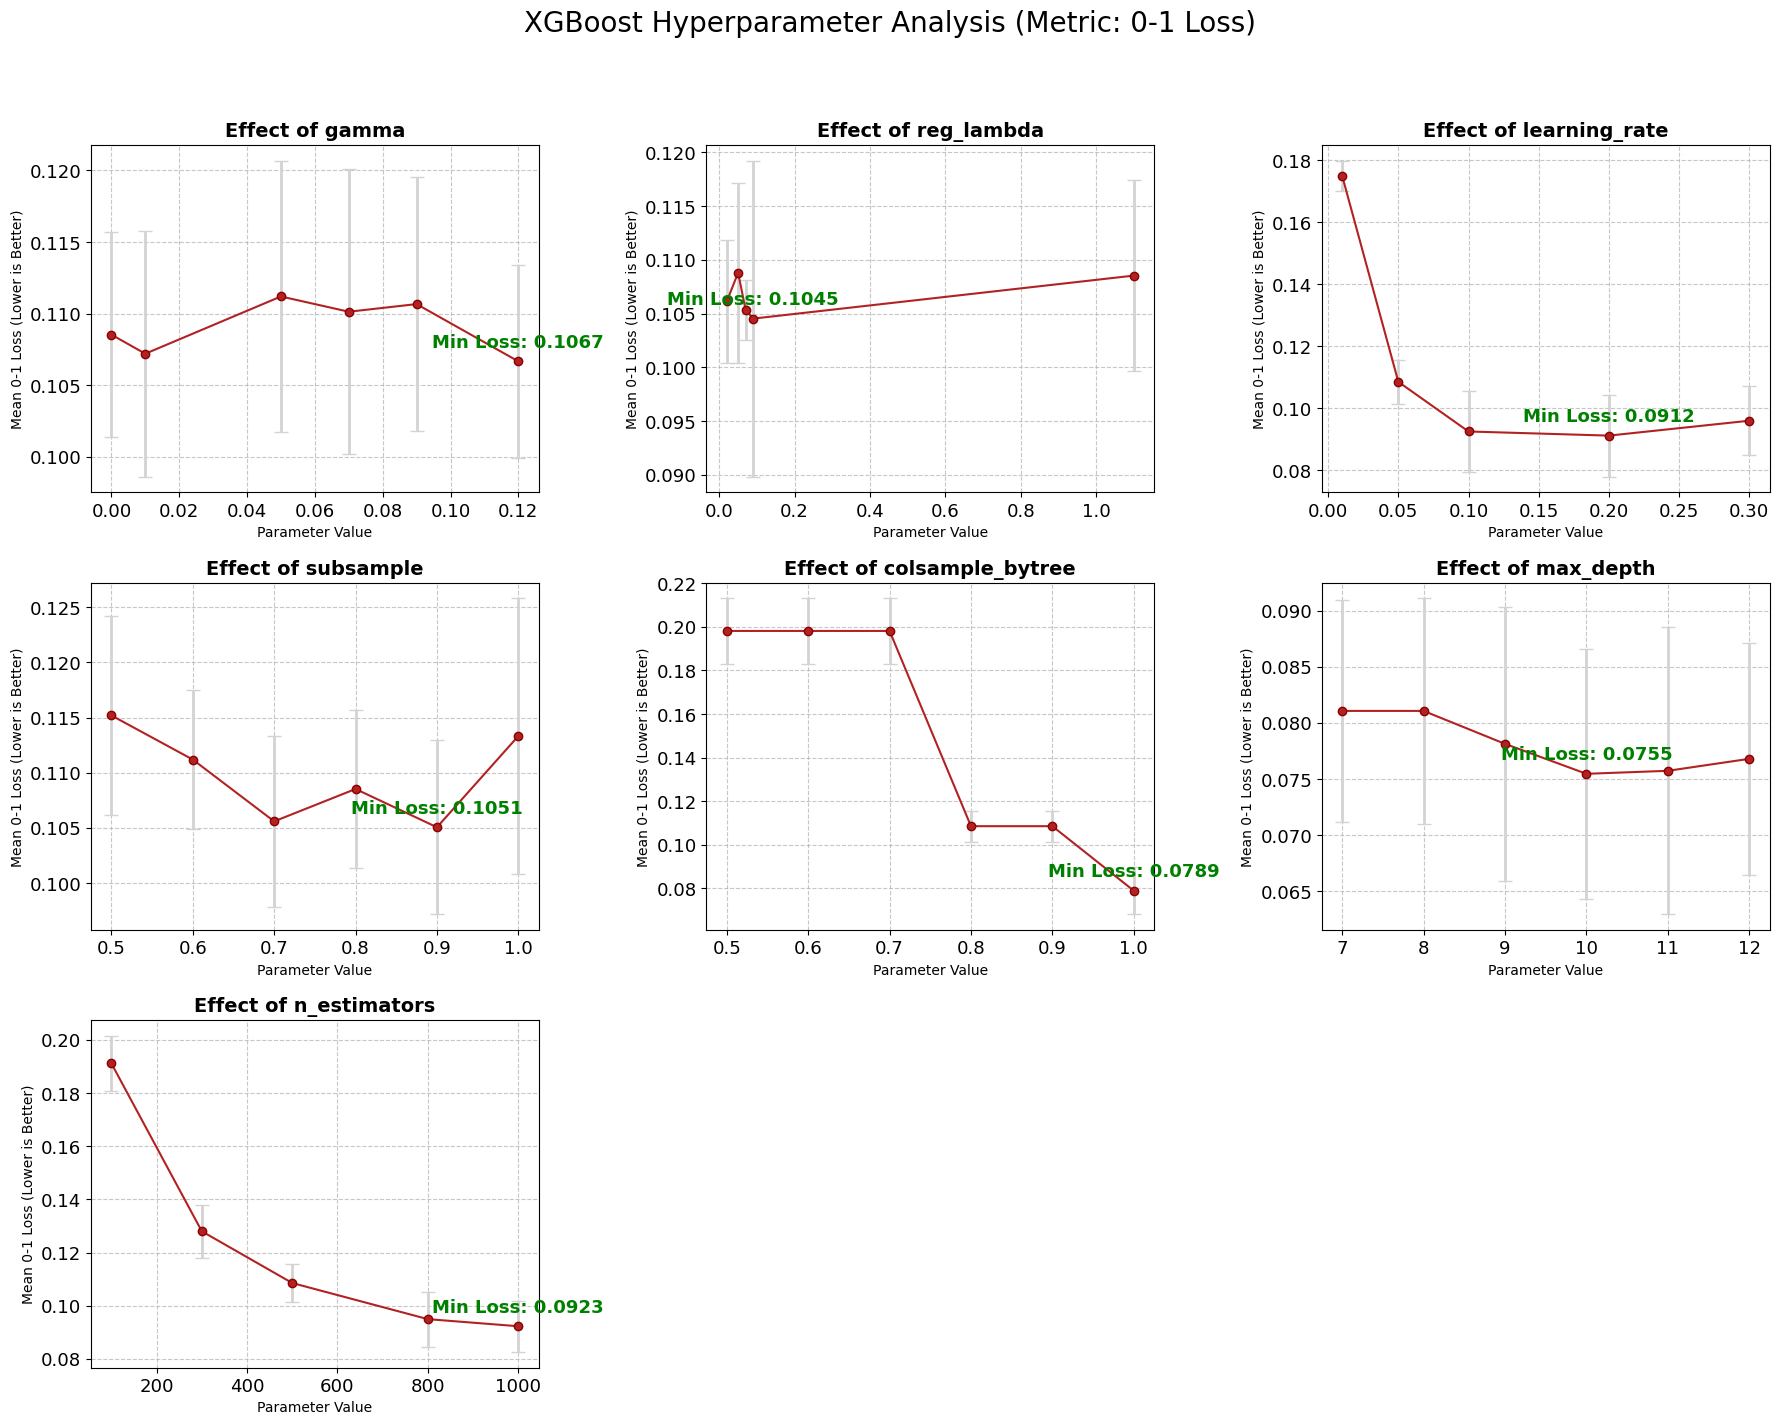

Best parameters found individually:
  - gamma: 0.12 (Loss: 0.10666666666666665)
  - reg_lambda: 0.09 (Loss: 0.10453333333333333)
  - learning_rate: 0.2 (Loss: 0.09120000000000002)
  - subsample: 0.9 (Loss: 0.10506666666666667)
  - colsample_bytree: 1.0 (Loss: 0.07893333333333334)
  - max_depth: 10 (Loss: 0.07546666666666668)
  - n_estimators: 1000 (Loss: 0.09226666666666665)

Full configuration for final model:
{'booster': 'gbtree', 'objective': 'binary:logistic', 'n_jobs': -1, 'scale_pos_weight': np.float64(0.9778481012658228), 'tree_method': 'hist', 'eval_metric': 'error', 'verbosity': 0, 'n_estimators': 1000, 'learning_rate': 0.2, 'max_depth': 10, 'subsample': 0.9, 'colsample_bytree': 1.0, 'gamma': 0.12, 'reg_lambda': 0.09}

Training final model on full dataset...
Final Test Accuracy: 0.9264
Final Test 0-1 Loss: 0.0736
shape of x_plot= (10201, 4)


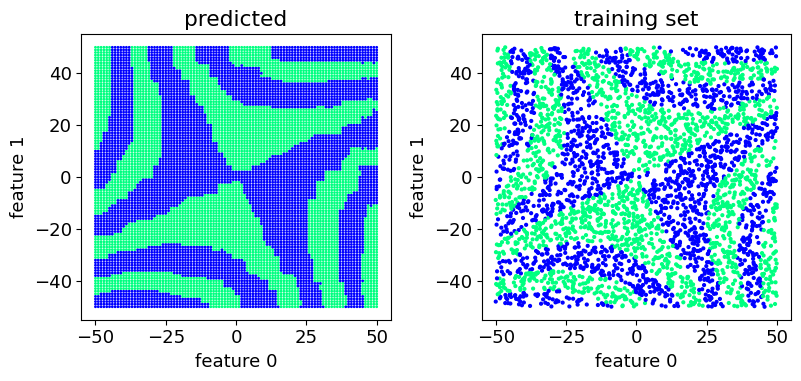

In [ ]:
# Base parameters
base_params = {
    "booster": "gbtree",  # model in use
    "objective": "binary:logistic",
    "n_jobs": -1,  # all cores in use
    "scale_pos_weight": ratio,
    "tree_method": "hist",  # method to build trees
    # specified eval_metric as the roc-auc score is also a viable option as it sets automatically
    #  the threshold for classification
    "eval_metric": "error",
    "verbosity": 0,  # remove technical messages
    "n_estimators": 500,
    "learning_rate": 0.05,
    "max_depth": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "gamma": 0,  # parameter that set threshold to acceptable improvement
    "reg_lambda": 1,
}

# Parameters to analyze and tested choices
params_to_test = {
    "gamma": [0, 0.01, 0.05, 0.07, 0.09, 0.12],
    "reg_lambda": [0.02, 0.05, 0.07, 0.09, 1.1],
    "learning_rate": [0.01, 0.05, 0.1, 0.2, 0.3],
    "subsample": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    "max_depth": [7, 8, 9, 10, 11, 12],
    "n_estimators": [100, 300, 500, 800, 1000],
}


results = {}
# K Fold setup
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# loop to change one parameter at the time, keeping standard values for the others
for param_name, param_values in params_to_test.items():
    means = []
    stds = []

    for value in param_values:
        current_params = base_params.copy()
        current_params[param_name] = value

        model = xgboost.XGBClassifier(**current_params)

        # Changed auc score to accuracy score also for parameter analysis
        scores_acc = cross_val_score(
            model, x_train, y_train, cv=cv_strategy, scoring="accuracy"
        )
        scores_error = 1 - scores_acc

        means.append(scores_error.mean())
        stds.append(scores_error.std())

    results[param_name] = {"values": param_values, "means": means, "stds": stds}

# setting parameters for graph
n_params = len(params_to_test)
n_cols = 3
n_rows = math.ceil(n_params / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
fig.suptitle("XGBoost Hyperparameter Analysis (Metric: 0-1 Loss)", fontsize=20)
axes = axes.flatten()

for i, (param_name, data) in enumerate(results.items()):
    ax = axes[i]
    x_vals = data["values"]
    y_means = data["means"]  # 0-1 loss
    y_errs = data["stds"]

    ax.errorbar(
        x_vals,
        y_means,
        yerr=y_errs,
        fmt="-o",
        capsize=5,
        color="firebrick",
        ecolor="lightgray",
        elinewidth=2,
        markeredgecolor="darkred",
    )

    ax.set_title(f"Effect of {param_name}", fontsize=14, fontweight="bold")
    ax.set_xlabel("Parameter Value", fontsize=10)
    ax.set_ylabel("Mean 0-1 Loss (Lower is Better)", fontsize=10)  # Label aggiornata
    ax.grid(True, linestyle="--", alpha=0.7)

    # Highlight the minumum value
    min_idx = np.argmin(y_means)
    ax.annotate(
        f"Min Loss: {y_means[min_idx]:.4f}",
        xy=(x_vals[min_idx], y_means[min_idx]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        color="green",
        fontweight="bold",
    )

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


# Training the whole dataset on the best found parameters and verify the performance
best_found_params = base_params.copy()

print("Best parameters found individually:")
for param_name, data in results.items():
    best_idx = np.argmin(data["means"])
    best_value = data["values"][best_idx]
    best_score = data["means"][best_idx]

    best_found_params[param_name] = best_value

    print(f"  - {param_name}: {best_value} (Loss: {best_score})")

print("\nFull configuration for final model:")
print(best_found_params)

# Train on whole dataset
print("\nTraining final model on full dataset...")
final_model = xgboost.XGBClassifier(**best_found_params)
final_model.fit(x_train, y_train)

# Final predictions
y_pred_final = final_model.predict(x_test)
y_prob_final = final_model.predict_proba(x_test)[:, 1]

acc_final = accuracy_score(y_test, y_pred_final)
zero_one_loss_final = 1 - acc_final

print(f"Final Test Accuracy: {acc_final}")
print(f"Final Test 0-1 Loss: {zero_one_loss_final}")

S = 50  # size of the square grid
dx = 1
x_seq = np.arange(-S, S + dx, dx)  # sequence of points for the grid
nx = len(x_seq)
x_plot = np.zeros((nx * nx, L))  # grid of points
print("shape of x_plot=", x_plot.shape)
q = 0
for i in range(nx):
    for j in range(nx):
        x_plot[q, :2] = [
            x_seq[i],
            x_seq[j],
        ]  # only the first two features are used for the artificial grid
        q += 1
y_plot = final_model.predict(x_plot)  # predict the labels of the grid points

fig, AX = plt.subplots(1, 2, figsize=(8.2, 4))
scat(AX[0], x_plot[:], y_plot, s=dx, title="predicted")
scat(AX[1], x_train[:], y_train, title="training set")
fig.tight_layout()
plt.show()

- gamma: since it rappresents the threshold of the error to stop trying to improve further the low value is expected but the fact that its different from 0 could indicate the fact that could prevent overfitting
- subsample: the fact that with a smaller subset for each tree we get a better result is another indicator of the fact that this parameter is fundamental to overcome overfitting
- colsample_bytree: this parameter selects a percentage of the columns, since there are 2 features that are just noise it's clear that selecting randomly the columns could bring to having worse result due to the possible presence in proportion of more useless data in the training
- max_depth: even though the best maximum depth is still high, due to generalization we can observe again that more complicated trees don't necessarily lead to better results 

## Ex 3.2

Final Test Accuracy with 1 features: 0.5856
Final Test 0-1 Loss with 1 features: 0.4144 (Error Rate)
Final Test Accuracy with 2 features: 0.9456
Final Test 0-1 Loss with 2 features: 0.0544 (Error Rate)
Final Test Accuracy with 3 features: 0.9368
Final Test 0-1 Loss with 3 features: 0.0632 (Error Rate)
Final Test Accuracy with 4 features: 0.9264
Final Test 0-1 Loss with 4 features: 0.0736 (Error Rate)


Text(0, 0.5, 'Accuracy')

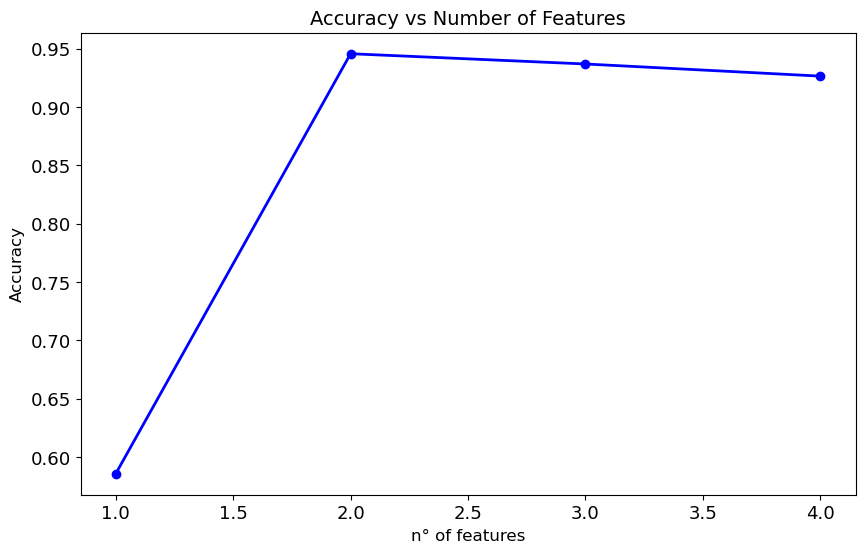

In [ ]:
accuracies = []
for i in range(1, x_train.shape[1] + 1):
    final_model = xgboost.XGBClassifier(**best_found_params)
    final_model.fit(x_train[:, 0:i], y_train)
    y_pred_final = final_model.predict(x_test[:, 0:i])
    y_prob_final = final_model.predict_proba(x_test[:, 0:i])[:, 1]

    acc_final = accuracy_score(y_test, y_pred_final)
    accuracies.append(acc_final)
    zero_one_loss_final = 1 - acc_final

    print(f"Final Test Accuracy with {i} features: {acc_final:.4f}")
    print(
        f"Final Test 0-1 Loss with {i} features: {zero_one_loss_final:.4f} (Error Rate)"
    )
plt.figure(figsize=(10, 6))
plt.plot(
    range(1, len(accuracies) + 1),
    accuracies,
    marker="o",
    color="b",
    linestyle="-",
    linewidth=2,
)
plt.title("Accuracy vs Number of Features", fontsize=14)
plt.xlabel("n° of features", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)

From this graph we can see how the presence of feratures that are purely noise  reduces the performance of the algorithm, even though the effect is not that great as the algorithm manages to recognize and divide according to the most significant features. 

In [ ]:
# best variable
best_gamma = results["gamma"]["values"][np.argmin(results["gamma"]["means"])]
best_reg_lambda = results["reg_lambda"]["values"][
    np.argmin(results["reg_lambda"]["means"])
]
best_learning_rate = results["learning_rate"]["values"][
    np.argmin(results["learning_rate"]["means"])
]
best_subsample = results["subsample"]["values"][
    np.argmin(results["subsample"]["means"])
]
best_colsample_bytree = results["colsample_bytree"]["values"][
    np.argmin(results["colsample_bytree"]["means"])
]
best_max_depth = results["max_depth"]["values"][
    np.argmin(results["max_depth"]["means"])
]
best_n_estimators = results["n_estimators"]["values"][
    np.argmin(results["n_estimators"]["means"])
]

## EX 3.3

## FFNN

We use the best parameters from Ex.1


In [ ]:
import numpy as np

from keras.models import Sequential
from keras.layers import Dense, Dropout

import matplotlib as mpl
import matplotlib.pyplot as plt

# default font
plt.rcParams["font.size"] = 13

from sklearn.preprocessing import StandardScaler

%run third-party/useful.py

In [5]:
import tensorflow.random as tf_r
import tensorflow as tf
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from sklearn.preprocessing import StandardScaler

/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


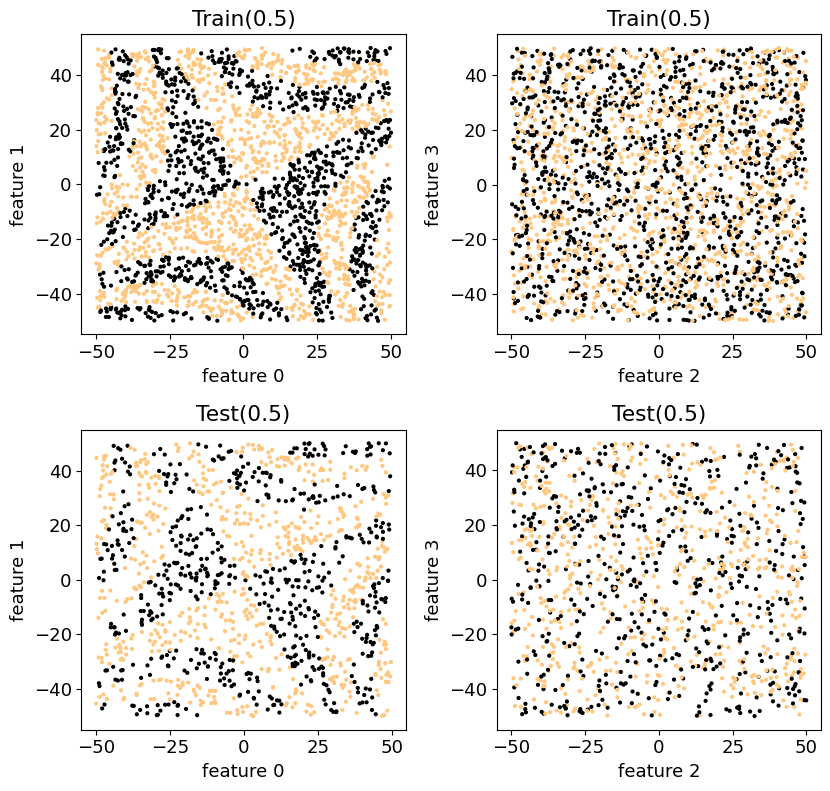

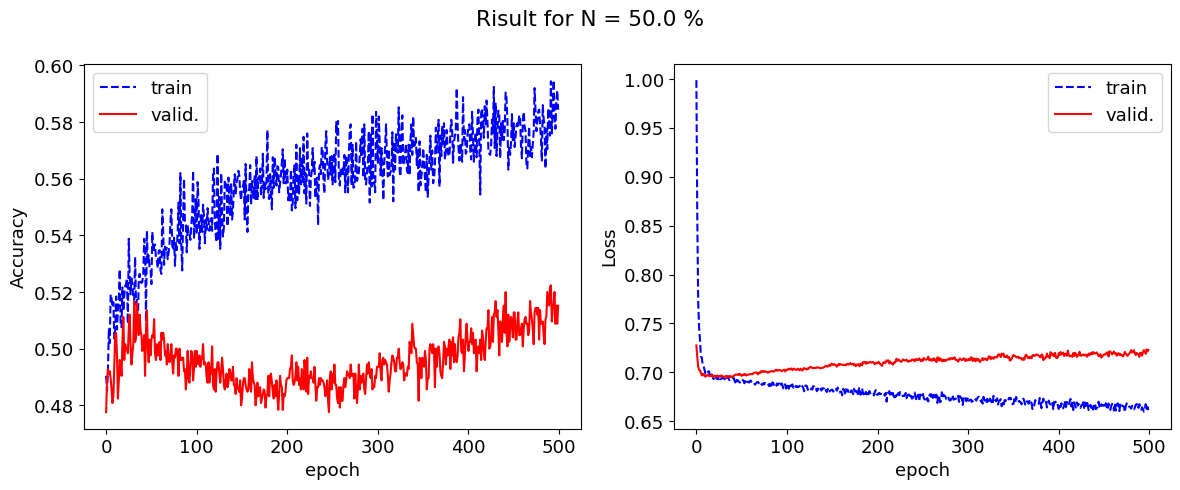

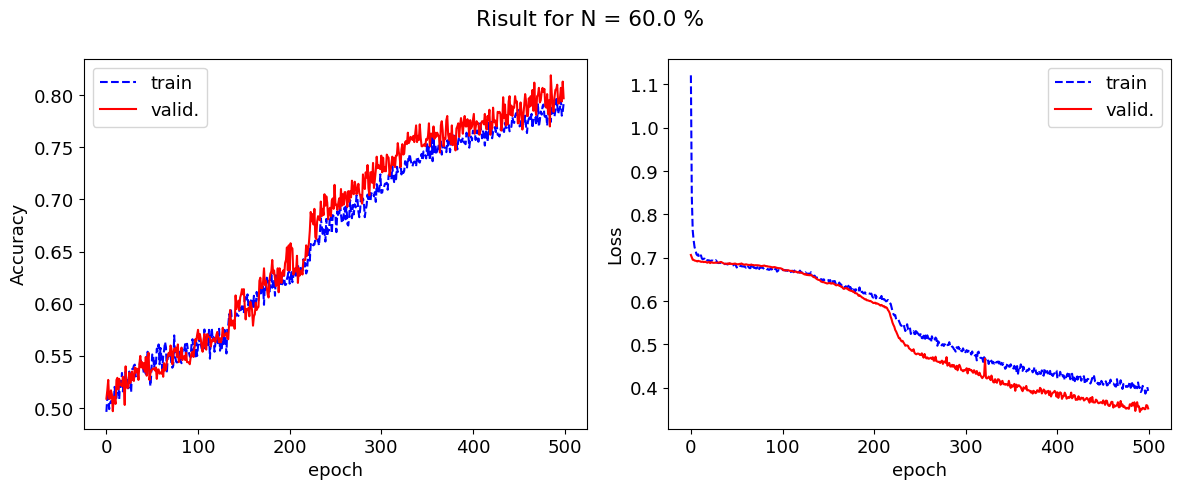

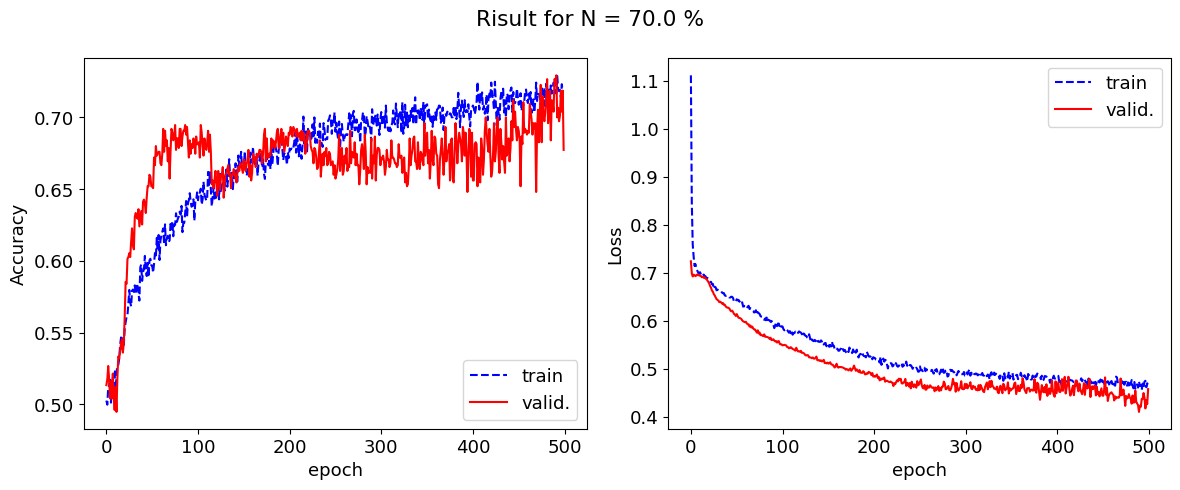

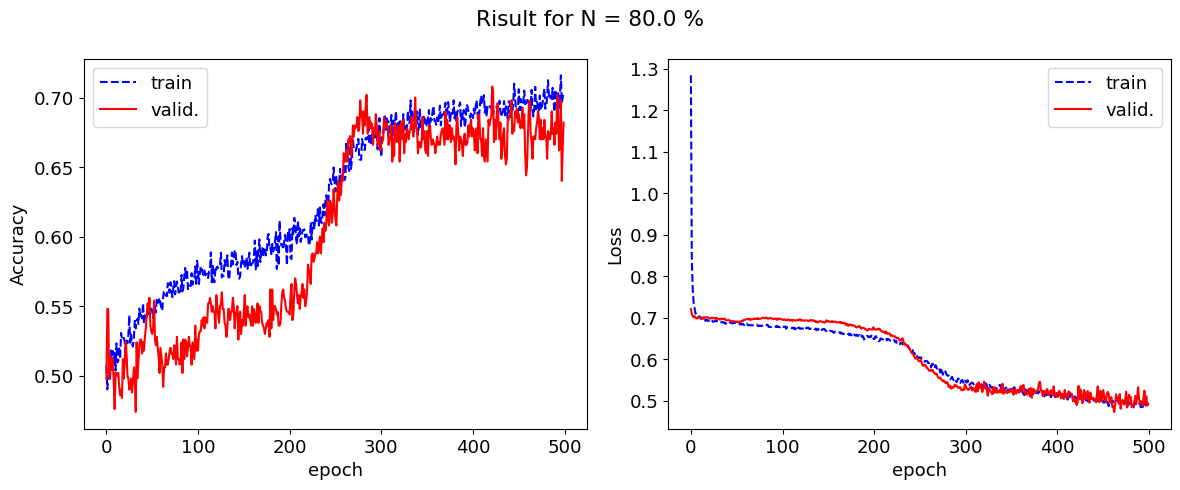

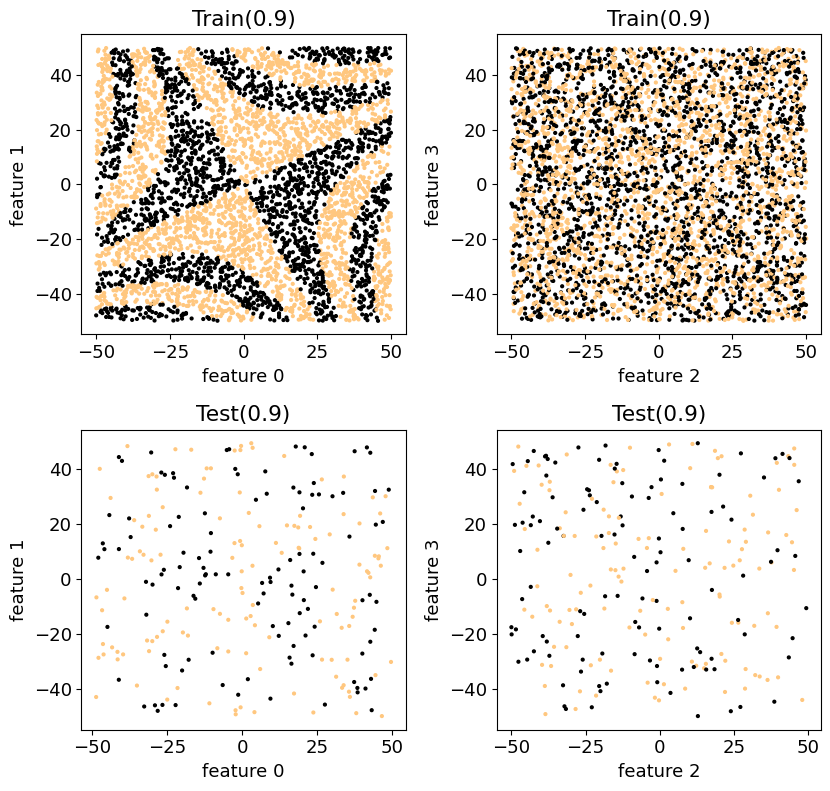

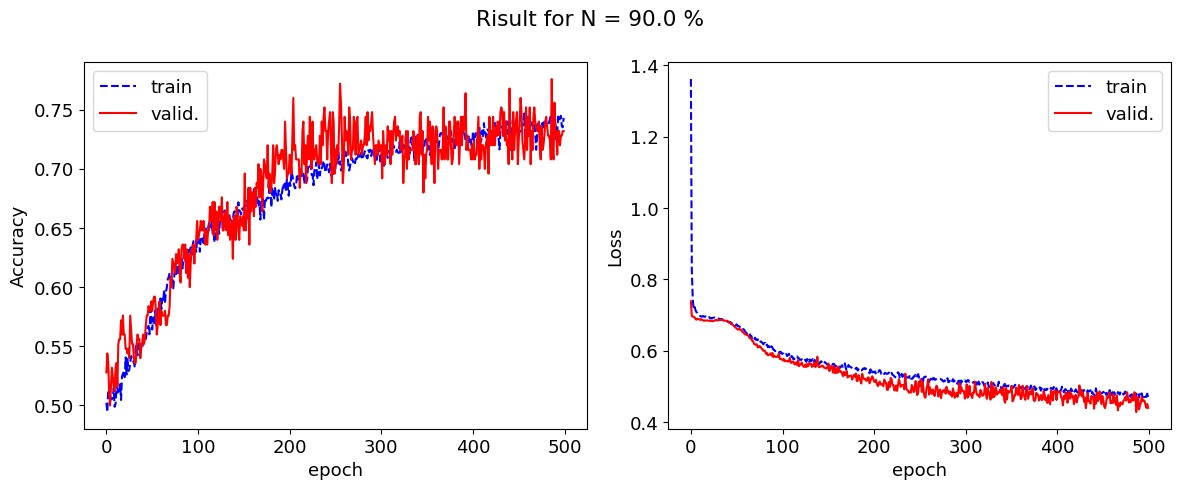

In [ ]:
train_acc_final = []
train_loss_final = []
valid_acc_final = []
valid_loss_final = []


test_loss_V = []
test_acc_V = []


def scat(ax, x, y, i=0, j=1, s=4, title=""):
    ax.scatter(x[:, i], x[:, j], s=s, c=y)
    ax.set_xlabel(f"feature {i}")
    ax.set_ylabel(f"feature {j}")
    ax.set_title(title)


per = [0.5, 0.6, 0.7, 0.8, 0.9]

N_subsets = [int(N * p) for p in per]

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

for p in per:
    # splitting data
    N_train = int(N * p)
    N_valid = int(N * ((1 + p) / 2))
    x_train, y_train = x[:N_train], y[:N_train]
    x_valid, y_valid = x[N_train:N_valid], y[N_train:N_valid]
    x_test, y_test = x[N_valid:], y[N_valid:]

    # scaler = StandardScaler()
    # x_train = scaler.fit_transform(x_train)
    # x_valid = scaler.transform(x_valid)
    # x_test = scaler.transform(x_test)

    np.random.seed(12345)
    tf_r.set_seed(12345)

    # model
    model = Sequential()
    model.add(Dense(L, input_shape=(L,), activation="relu"))
    model.add(Dense(20, activation="elu"))
    model.add(Dropout(0.1))
    model.add(Dense(20, activation="elu"))
    model.add(Dropout(0.1))
    model.add(Dense(20, activation="elu"))
    model.add(Dropout(0.1))
    model.add(Dense(1, activation="sigmoid"))
    nepoch = 500

    # print(model.summary())

    # optimizer
    opt = RMSprop(learning_rate=0.001, rho=0.9)
    model.compile(loss="binary_crossentropy", optimizer=opt, metrics=["accuracy"])

    if p == 0.5 or p == 0.9:
        fig, AX = plt.subplots(2, 2, figsize=(8.5, 8.1))
        scat(AX[0, 0], x_train, y_train, title=f"Train({p})")
        scat(AX[0, 1], x_train, y_train, i=2, j=3, title=f"Train({p})")
        scat(AX[1, 0], x_test, y_test, title=f"Test({p})")
        scat(AX[1, 1], x_test, y_test, i=2, j=3, title=f"Test({p})")
        fig.tight_layout()
        plt.show()

    # training
    # callback = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=200, restore_best_weights=True) #early stop

    fit = model.fit(
        x_train,
        y_train,
        epochs=nepoch,
        batch_size=50,
        validation_data=(x_valid, y_valid),
        verbose=0,
        # callbacks=[callback]
    )

    # accuracy and error
    train_acc_final.append(fit.history["accuracy"][-1])
    train_loss_final.append(fit.history["loss"][-1])
    valid_acc_final.append(fit.history["val_accuracy"][-1])
    valid_loss_final.append(fit.history["val_loss"][-1])
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    test_loss_V.append(test_loss)
    test_acc_V.append(test_acc)

    # plot
    fig, AX = plt.subplots(1, 2, figsize=(12, 5.0))
    ax = AX[0]
    ax.plot(fit.history["accuracy"], label="train", c="b", ls="--")
    ax.plot(fit.history["val_accuracy"], label="valid.", c="r")
    ax.set_xlabel("epoch")
    ax.set_ylabel("Accuracy")
    ax.legend()
    ax = AX[1]
    ax.plot(fit.history["loss"], label="train", c="b", ls="--")
    ax.plot(fit.history["val_loss"], label="valid.", c="r")
    ax.set_xlabel("epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    plt.suptitle(f"Risult for N = {p * 100} %")
    plt.tight_layout()
    plt.show()

From plot we can notice that a good accuracy start from 60%.

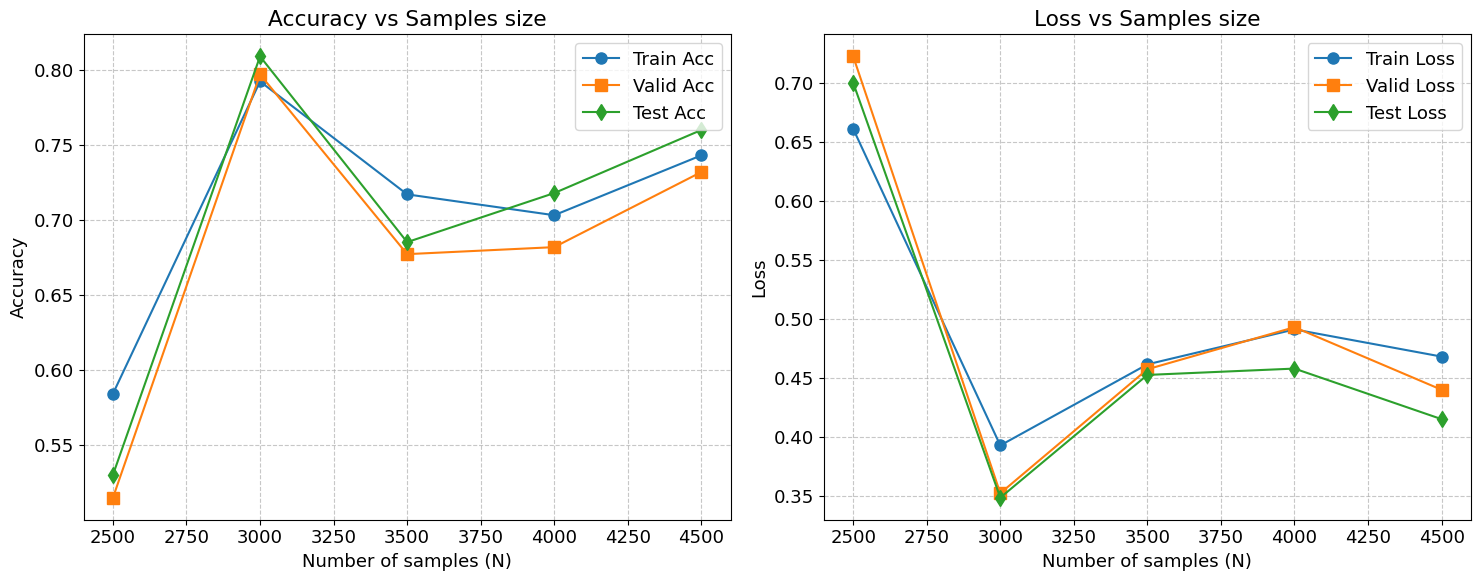

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.plot(N_subsets, train_acc_final, "o-", label="Train Acc", markersize=8)
ax1.plot(N_subsets, valid_acc_final, "s-", label="Valid Acc", markersize=8)
ax1.plot(N_subsets, test_acc_V, "d-", label="Test Acc", markersize=8)
ax1.set_xlabel("Number of samples (N)")
ax1.set_ylabel("Accuracy")
ax1.set_title("Accuracy vs Samples size")
ax1.grid(True, linestyle="--", alpha=0.7)
ax1.legend()

ax2.plot(N_subsets, train_loss_final, "o-", label="Train Loss", markersize=8)
ax2.plot(N_subsets, valid_loss_final, "s-", label="Valid Loss", markersize=8)
ax2.plot(N_subsets, test_loss_V, "d-", label="Test Loss", markersize=8)
ax2.set_xlabel("Number of samples (N)")
ax2.set_ylabel("Loss")
ax2.set_title("Loss vs Samples size")
ax2.grid(True, linestyle="--", alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()

We notice a decrease of accuracy after 60% .
Probably we need more epoch to fit a bigger size of training, to have a better accuracy.


## XGB

As parameters are used the best found in the prevoius section about XGB

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
import xgboost
from xgboost import XGBClassifier
from xgboost import plot_importance, to_graphviz, plot_tree
from sklearn.metrics import log_loss
from sklearn.model_selection import cross_val_score

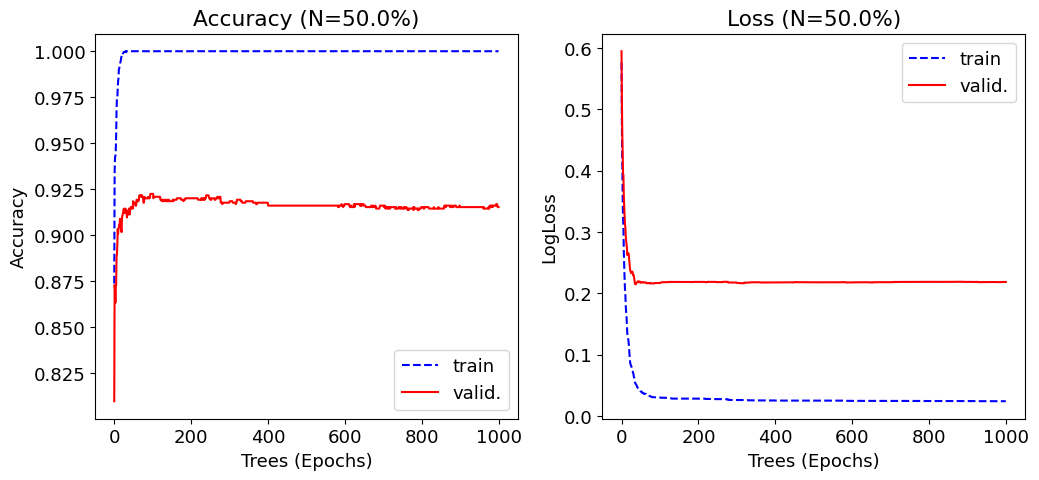

p=0.5 -> Accuracy Test: 0.909


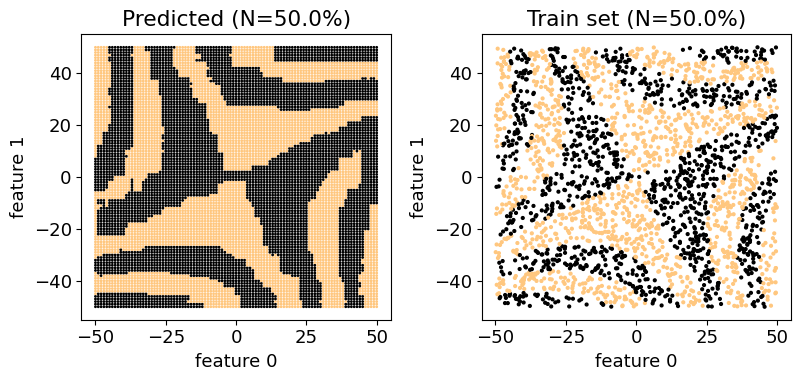

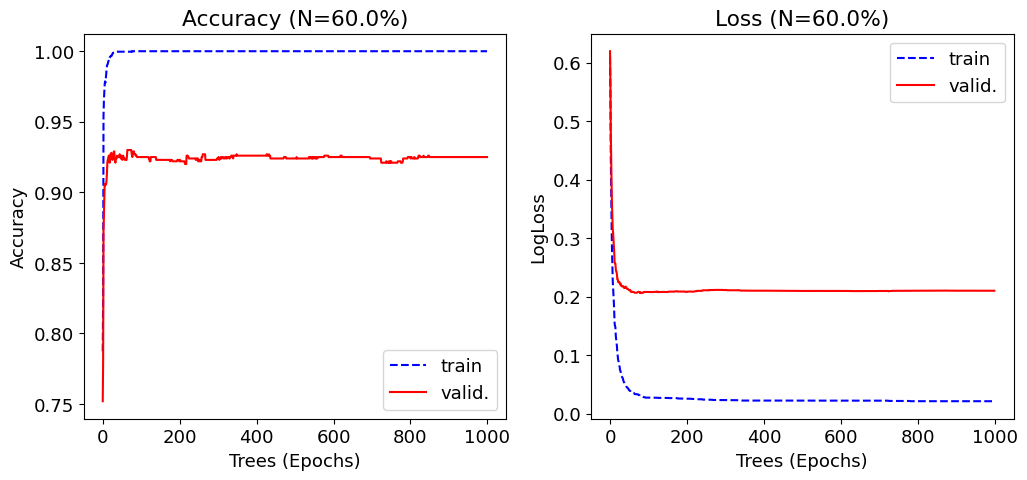

p=0.6 -> Accuracy Test: 0.924


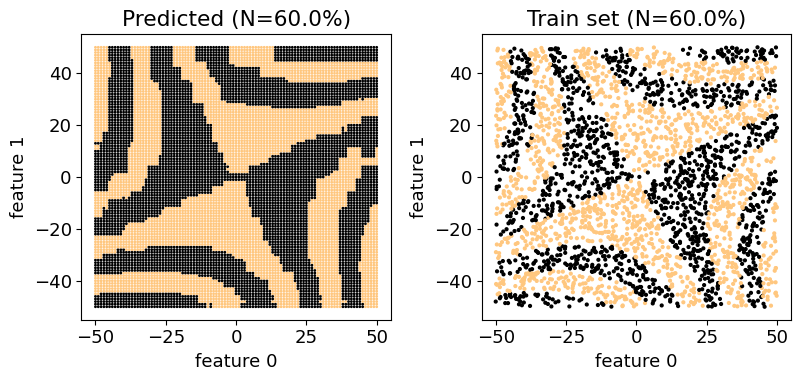

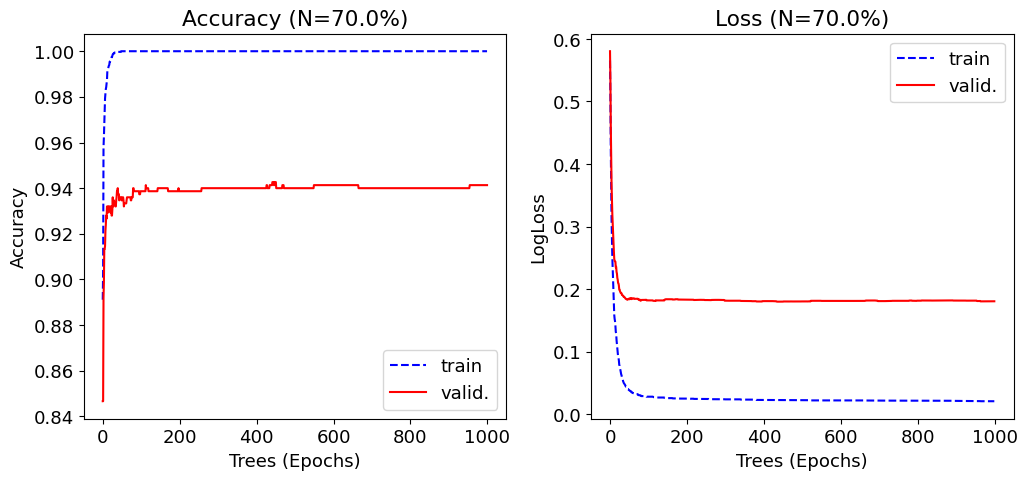

p=0.7 -> Accuracy Test: 0.932


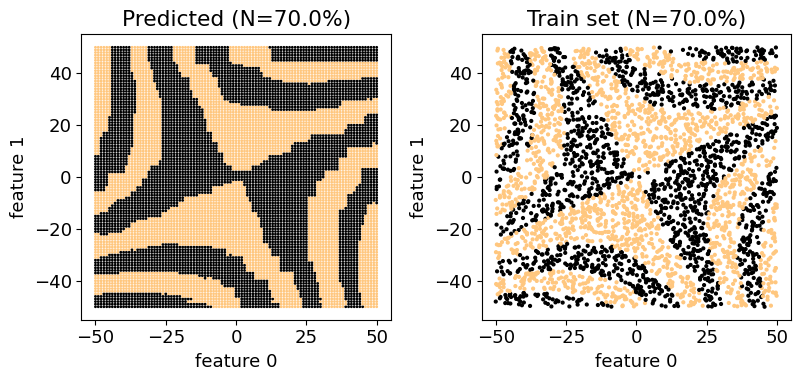

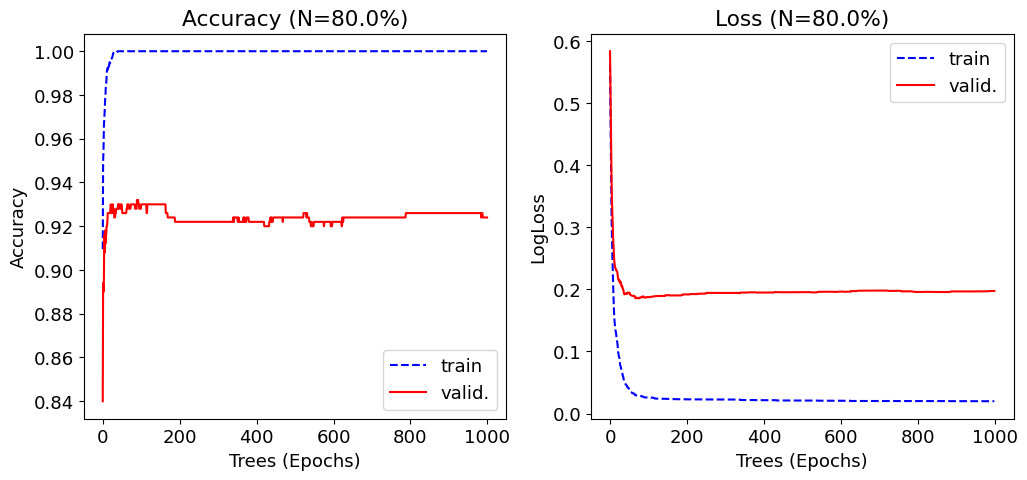

p=0.8 -> Accuracy Test: 0.930


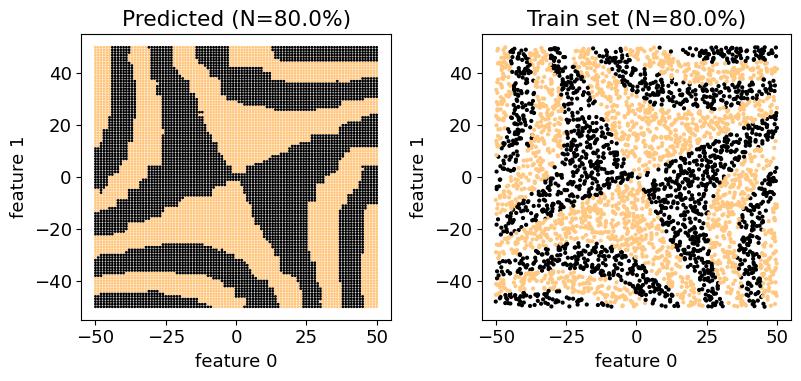

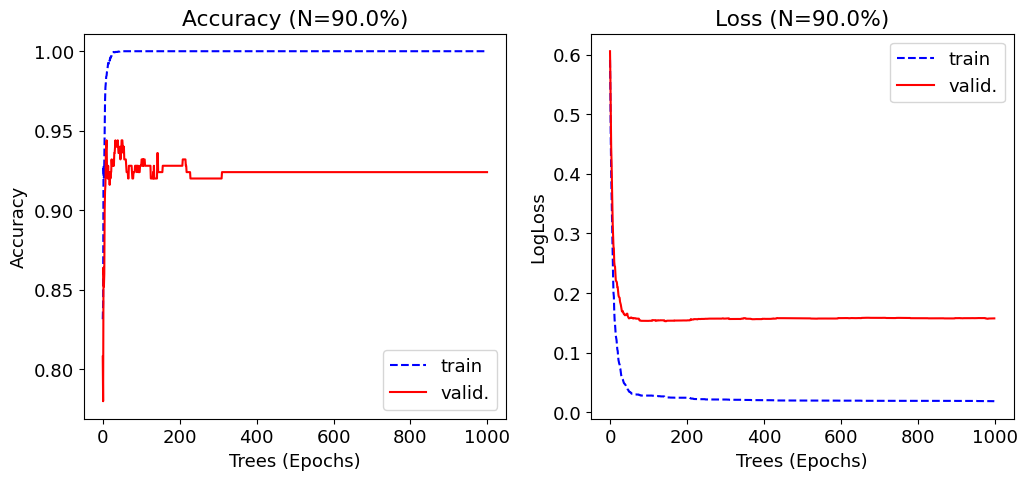

p=0.9 -> Accuracy Test: 0.952


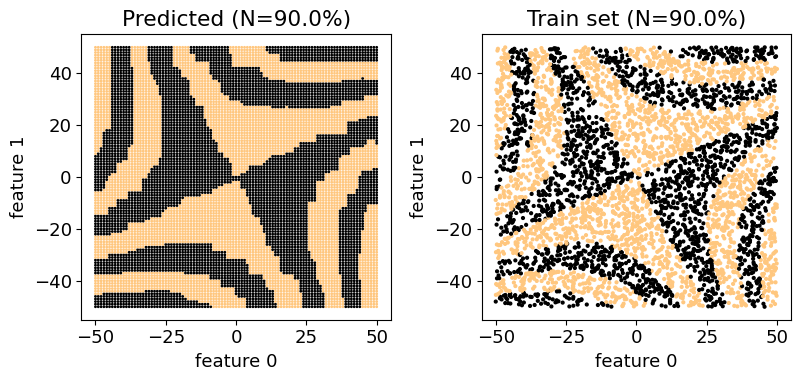

In [ ]:
train_acc_final_X = []
train_loss_final_X = []
valid_acc_final_X = []
valid_loss_final_X = []
test_loss_V_X = []
test_acc_V_X = []


def scat(ax, x, y, i=0, j=1, s=4, title=""):
    ax.scatter(x[:, i], x[:, j], s=s, c=y)
    ax.set_xlabel(f"feature {i}")
    ax.set_ylabel(f"feature {j}")
    ax.set_title(title)


per = [0.5, 0.6, 0.7, 0.8, 0.9]

N_subset = [int(N * p) for p in per]

for p in per:
    N_train = int(N * p)
    N_valid = int(N * (1 + p) / 2)
    x_train, y_train = x[:N_train], y[:N_train]
    x_valid, y_valid = x[N_train:N_valid], y[N_train:N_valid]
    x_test, y_test = x[N_valid:], y[N_valid:]

    model = XGBClassifier(
        seed=1,
        objective="binary:logistic",
        importance_type="gain",
        gamma=best_gamma,
        reg_lambda=best_reg_lambda,
        learning_rate=best_learning_rate,
        subsample=best_subsample,
        colsample_bytree=best_colsample_bytree,
        max_depth=best_max_depth,
        n_estimators=best_n_estimators,
        eval_metric=["error", "logloss"],
    )

    def classify(clf=model, show=False):
        clf.fit(
            x_train,
            y_train,
            eval_set=[(x_train, y_train), (x_valid, y_valid)],
            verbose=False,
        )

        results = clf.evals_result()
        epochs = len(results["validation_0"]["logloss"])
        x_axis = range(0, epochs)

        fig, AX = plt.subplots(1, 2, figsize=(12, 5))

        ax = AX[0]
        train_acc = [1 - e for e in results["validation_0"]["error"]]
        valid_acc = [1 - e for e in results["validation_1"]["error"]]
        ax.plot(x_axis, train_acc, label="train", c="b", ls="--")
        ax.plot(x_axis, valid_acc, label="valid.", c="r")
        ax.set_title(f"Accuracy (N={p * 100}%)")
        ax.set_xlabel("Trees (Epochs)")
        ax.set_ylabel("Accuracy")
        ax.legend()

        ax = AX[1]
        ax.plot(
            x_axis, results["validation_0"]["logloss"], label="train", c="b", ls="--"
        )
        ax.plot(x_axis, results["validation_1"]["logloss"], label="valid.", c="r")
        ax.set_title(f"Loss (N={p * 100}%)")
        ax.set_xlabel("Trees (Epochs)")
        ax.set_ylabel("LogLoss")
        ax.legend()
        plt.show()

        train_acc_final_X.append(train_acc[-1])
        train_loss_final_X.append(results["validation_0"]["logloss"][-1])

        valid_acc_final_X.append(valid_acc[-1])
        valid_loss_final_X.append(results["validation_1"]["logloss"][-1])

        test_acc = clf.score(x_test, y_test)
        test_acc_V_X.append(test_acc)

        y_probs = clf.predict_proba(x_test)
        t_loss = log_loss(y_test, y_probs)
        test_loss_V_X.append(t_loss)

        y_hat = clf.predict(x_test)
        print(f"p={p} -> Accuracy Test: {test_acc:.3f}")

        S = 50
        dx = 1
        x_seq = np.arange(-S, S + dx, dx)
        nx = len(x_seq)
        x_plot = np.zeros((nx * nx, L))
        q = 0
        for i in range(nx):
            for j in range(nx):
                x_plot[q, :2] = [x_seq[i], x_seq[j]]
                q += 1

        y_plot = clf.predict(x_plot)

        fig, AX_scat = plt.subplots(1, 2, figsize=(8.2, 4))
        scat(AX_scat[0], x_plot, y_plot, s=dx, title=f"Predicted (N={p * 100}%)")
        scat(AX_scat[1], x_train, y_train, title=f"Train set (N={p * 100}%)")
        plt.tight_layout()
        plt.show()

        if show:
            pass

    classify(model, show=False)


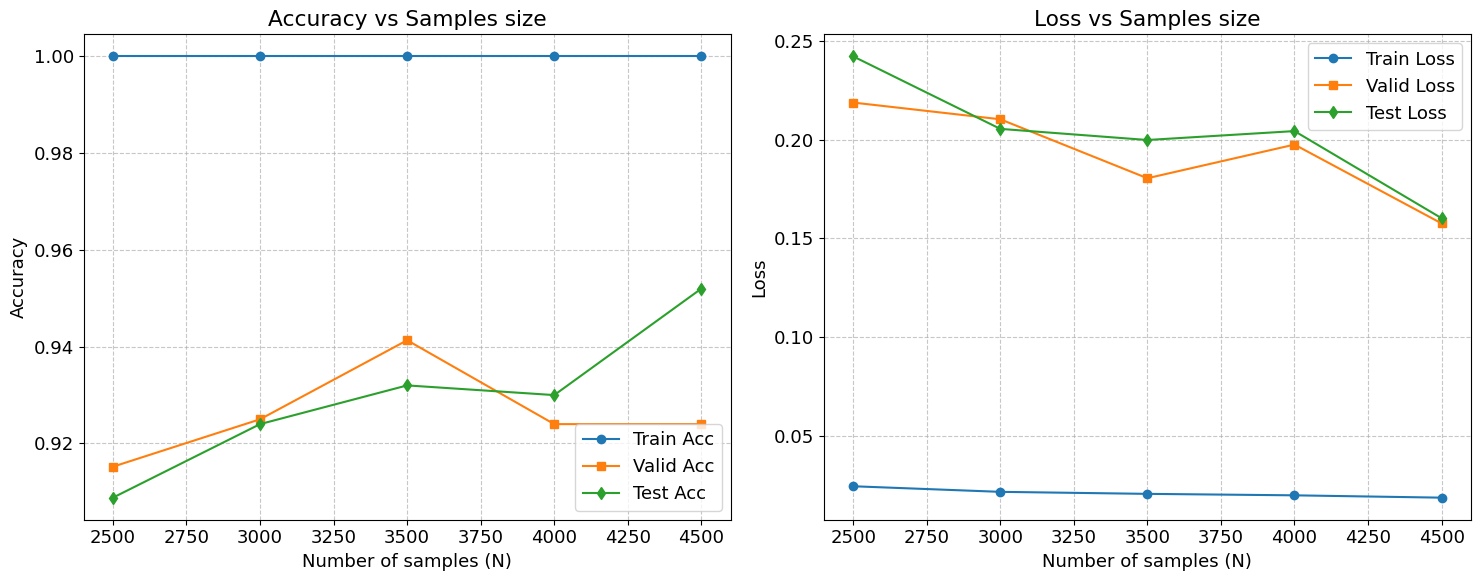

In [ ]:
N_plot = [int(N * p) for p in per]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.plot(N_plot, train_acc_final_X, "o-", label="Train Acc")
ax1.plot(N_plot, valid_acc_final_X, "s-", label="Valid Acc")
ax1.plot(N_plot, test_acc_V_X, "d-", label="Test Acc")
ax1.set_xlabel("Number of samples (N)")
ax1.set_ylabel("Accuracy")
ax1.set_title("Accuracy vs Samples size")
ax1.grid(True, linestyle="--", alpha=0.7)
ax1.legend()

ax2.plot(N_plot, train_loss_final_X, "o-", label="Train Loss")
ax2.plot(N_plot, valid_loss_final_X, "s-", label="Valid Loss")
ax2.plot(N_plot, test_loss_V_X, "d-", label="Test Loss")
ax2.set_xlabel("Number of samples (N)")
ax2.set_ylabel("Loss")
ax2.set_title("Loss vs Samples size")
ax2.grid(True, linestyle="--", alpha=0.7)
ax2.legend()

plt.tight_layout()
plt.show()

We can notice that the Accuracy is very good also for low training dimension 

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))

ax1.plot(N_plot, train_acc_final_X, "o-", label="Train Acc XG", markersize=8)
ax1.plot(N_plot, train_acc_final, "s-", label="Train Acc FFNN", markersize=8)
ax1.set_xlabel("Number of samples (N)")
ax1.set_ylabel("Accuracy")
ax1.set_title("Accuracy Training vs Samples size")
ax1.grid(True, linestyle="--", alpha=0.7)
ax1.legend()

ax2.plot(N_plot, valid_acc_final_X, "d-", label="Valid Acc XG", markersize=8)
ax2.plot(N_plot, valid_acc_final, "s-", label="Valid Acc FFNN", markersize=8)
ax2.set_xlabel("Number of samples (N)")
ax2.set_ylabel("Accuracy")
ax2.set_title("Accuracy Validation vs Samples size")
ax2.grid(True, linestyle="--", alpha=0.7)
ax2.legend()

ax3.plot(N_plot, test_acc_V_X, "o-", label="Train Acc XG", markersize=8)
ax3.plot(N_plot, test_acc_V, "s-", label="Train Acc FFNN", markersize=8)
ax3.set_xlabel("Number of samples (N)")
ax3.set_ylabel("Accuracy")
ax3.set_title("Accuracy Test vs Samples size")
ax3.grid(True, linestyle="--", alpha=0.7)
ax3.legend()

## Cross Validation (CV)

/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activi

p = 0.5 | XGB: 0.898 | FFNN: 0.502


/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activi

p = 0.6 | XGB: 0.909 | FFNN: 0.522


/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activi

...

p = 0.8 | XGB: 0.923 | FFNN: 0.522


/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activi

p = 0.9 | XGB: 0.926 | FFNN: 0.520


/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/niccolo/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activi

p = 1 | XGB: 0.935 | FFNN: 0.518


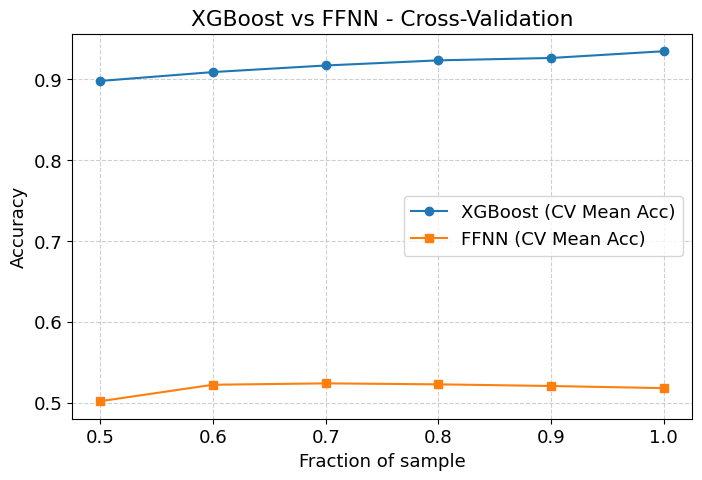

In [ ]:
from sklearn.model_selection import KFold, cross_val_score
import numpy as np
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler

n_folds = 3
kf = KFold(n_splits=n_folds, shuffle=True, random_state=12345)


cv_results_xgb = []
cv_results_ffnn = []

per_fold = [0.5, 0.6, 0.7, 0.8, 0.9, 1]

for p in per_fold:
    N_sub = int(N * p)
    x_sub, y_sub = x[:N_sub], y[:N_sub]

    model_xgb = XGBClassifier(
        objective="binary:logistic",
        seed=1,
        eval_metric="logloss",
        gamma=best_gamma,
        reg_lambda=best_reg_lambda,
        learning_rate=best_learning_rate,
        subsample=best_subsample,
        colsample_bytree=best_colsample_bytree,
        max_depth=best_max_depth,
        n_estimators=best_n_estimators,
    )
    scores_xgb = cross_val_score(model_xgb, x_sub, y_sub, cv=kf, scoring="accuracy")
    cv_results_xgb.append(np.mean(scores_xgb))

    fold_accs = []
    for train_idx, val_idx in kf.split(x_sub):
        x_t, x_v = x_sub[train_idx], x_sub[val_idx]
        y_t, y_v = y_sub[train_idx], y_sub[val_idx]

        scaler = StandardScaler()
        x_t = scaler.fit_transform(x_t)
        x_v = scaler.transform(x_v)

        tf.keras.backend.clear_session()
        np.random.seed(123)
        tf.random.set_seed(123)

        model_nn = Sequential(
            [
                Dense(L, input_shape=(L,), activation="relu"),
                Dense(20, activation="elu"),
                Dropout(0.1),
                Dense(20, activation="elu"),
                Dropout(0.1),
                Dense(20, activation="elu"),
                Dropout(0.1),
                Dense(1, activation="sigmoid"),
            ]
        )

        # stop_early = EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)

        model_nn.compile(
            loss="binary_crossentropy", optimizer=RMSprop(0.001), metrics=["accuracy"]
        )

        model_nn.fit(
            x_t,
            y_t,
            epochs=100,  # smaller epoch for speed
            batch_size=8,  # smaller bunch size
            validation_data=(x_v, y_v),
            # callbacks=[stop_early],
            verbose=0,
        )

        _, acc = model_nn.evaluate(x_v, y_v, verbose=0)
        fold_accs.append(acc)
    cv_results_ffnn.append(np.mean(fold_accs))
    print(f"p = {p} | XGB: {cv_results_xgb[-1]:.3f} | FFNN: {cv_results_ffnn[-1]:.3f}")


plt.figure(figsize=(8, 5))
plt.plot(per_fold, cv_results_xgb, "o-", label="XGBoost (CV Mean Acc)")
plt.plot(per_fold, cv_results_ffnn, "s-", label="FFNN (CV Mean Acc)")
plt.xlabel("Fraction of sample")
plt.ylabel("Accuracy")
plt.title("XGBoost vs FFNN - Cross-Validation")
plt.legend()
plt.grid(True, ls="--", alpha=0.6)
plt.show()

As expected, the accuracy of XGBoost is higher than that of the FFNN. As shown above, Neural Networks do not perform optimally with small datasets. In our K-fold cross-validation, the data is split into 3 small subsets, which prevents the FFNN from being adequately trained.